In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import carregar_noaa_por_tipo, carregar_bacias, pareados_por_raio, tabela_ajustes, plotar_mosaico

tipos = carregar_noaa_por_tipo()
pontos = {nome: tipos[nome] for nome in ("Água oceânica", "Areia de praia")}
bacias = carregar_bacias(pontos)
print({nome: len(df) for nome, df in pontos.items()}, "| bacias (100%, sem corte de área):", len(bacias))

{'Água oceânica': 14363, 'Areia de praia': 893} | bacias (100%, sem corte de área): 180583


In [2]:
pareados = pareados_por_raio(bacias, pontos, raios=(5, 22))
print(tabela_ajustes(pareados, pop_mins=(0, 1000, 10000)).round(3).to_string(index=False))

      Conjunto  R_km  Pop_min                X    N   beta    se  r2_pct  p_value    rho  r2_bins_pct  beta_bins_w
 Água oceânica     5        0 total_population  754  0.346 0.032  13.246    0.000  0.418       96.382        0.344
 Água oceânica     5        0         area_km2  754  0.575 0.092   4.970    0.000  0.315       42.263        0.553
 Água oceânica     5     1000 total_population  421  0.601 0.084  10.920    0.000  0.384       91.232        0.621
 Água oceânica     5     1000         area_km2  421  0.371 0.116   2.374    0.002  0.211       17.118        0.235
 Água oceânica     5    10000 total_population  202  0.519 0.161   4.919    0.002  0.187       75.465        0.462
 Água oceânica     5    10000         area_km2  202  0.082 0.145   0.161    0.571  0.023       50.314       -0.094
Areia de praia     5        0 total_population  333  0.201 0.057   3.605    0.000  0.205       35.561        0.187
Areia de praia     5        0         area_km2  333  0.170 0.103   0.821    0.09

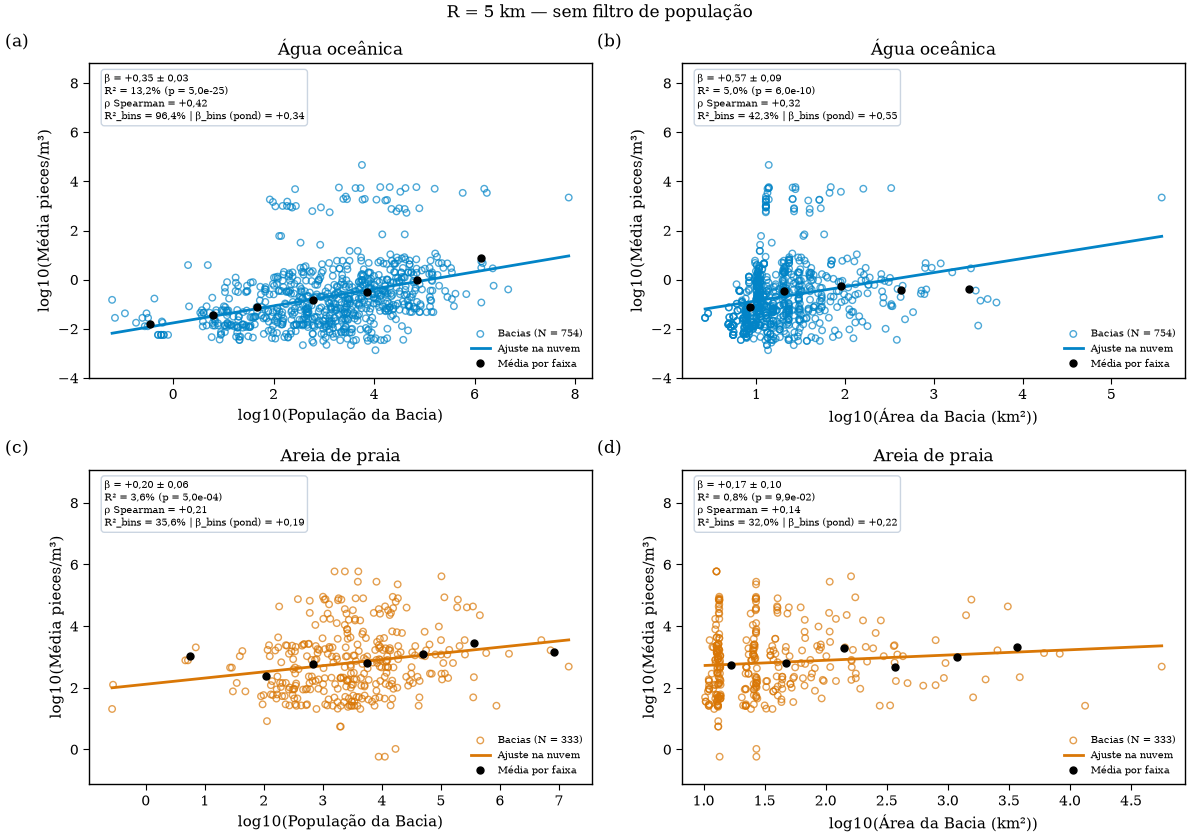

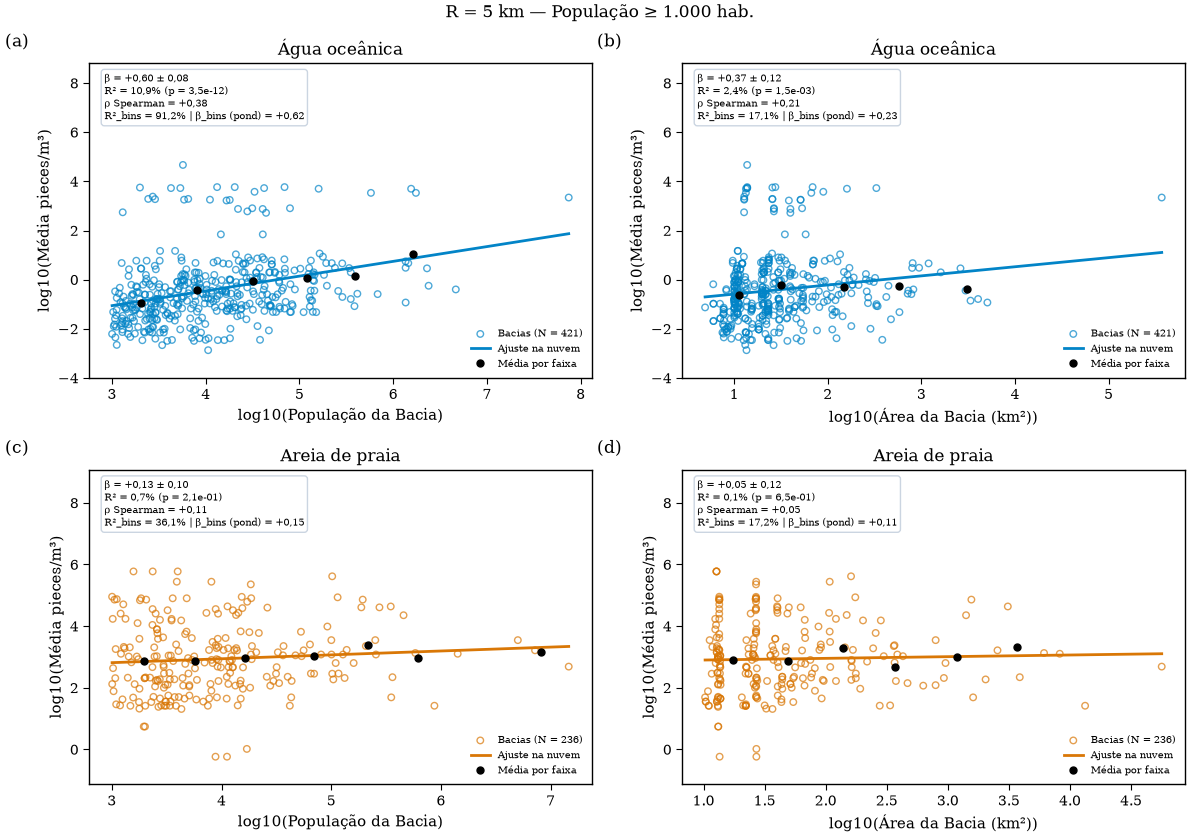

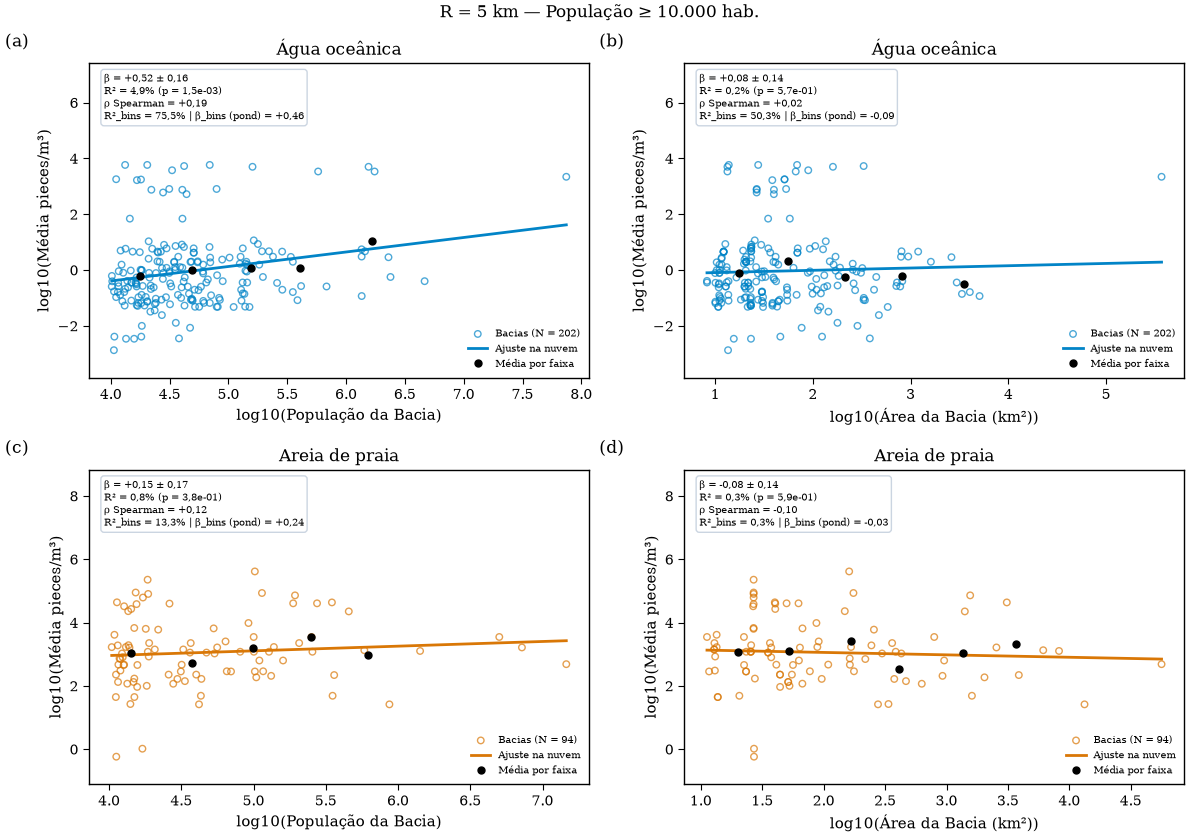

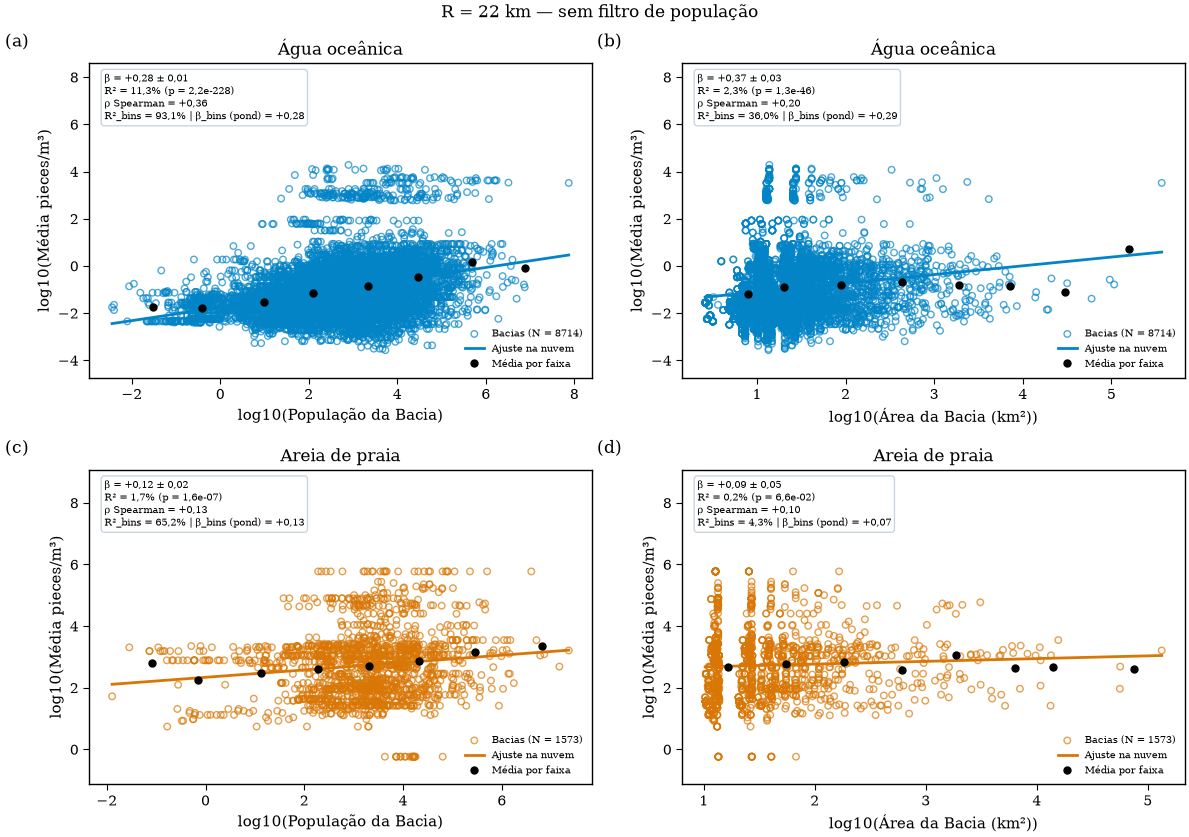

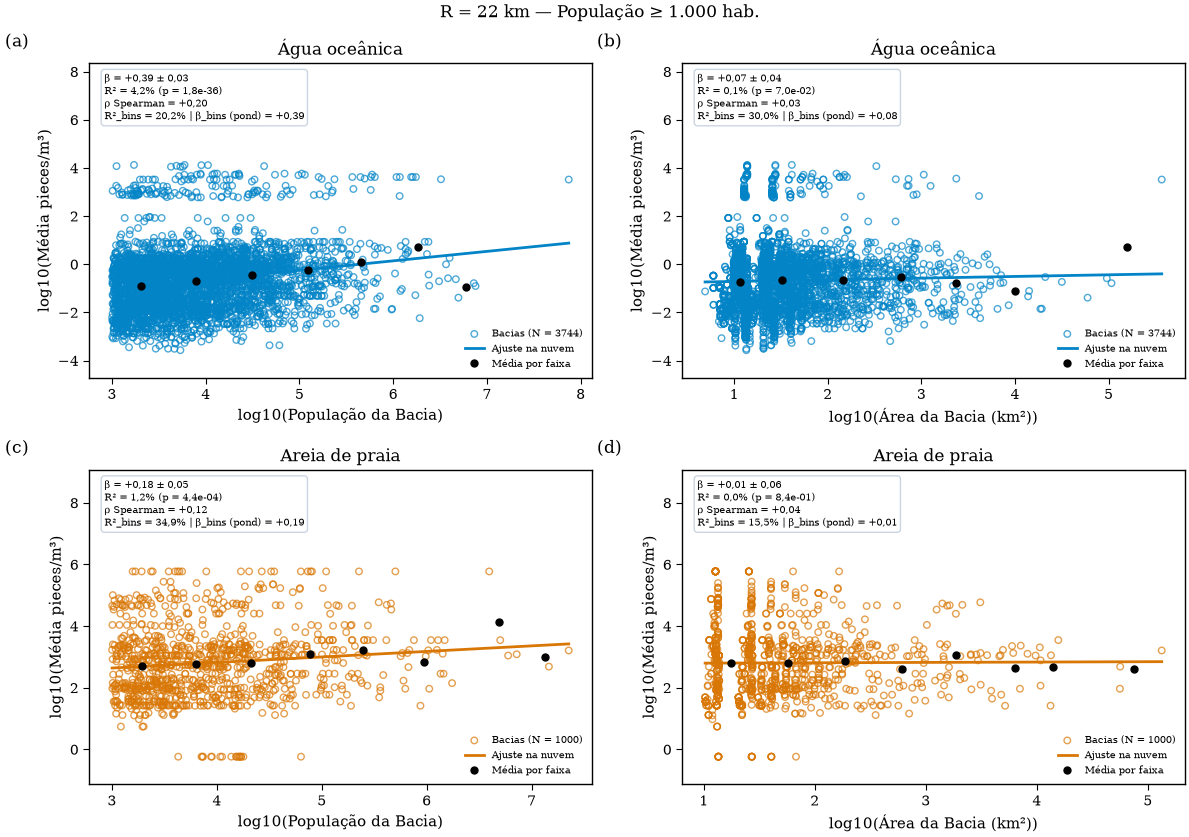

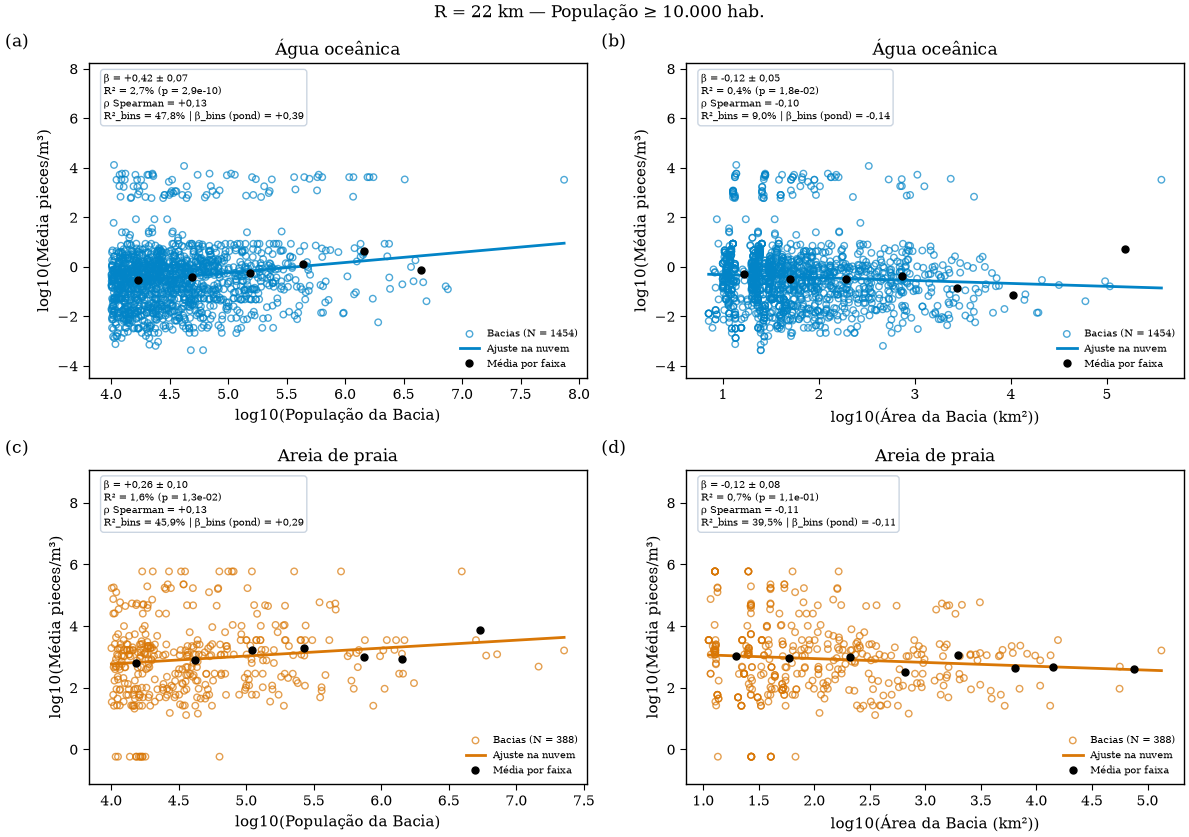

In [3]:
for r in (5, 22):
    for pop_min in (0, 1000, 10000):
        plotar_mosaico(pareados[r], f"R = {r} km", pop_min, arquivo=f"mosaico_agua_areia_R{r}_pop{pop_min}")